# EcoFOCIpy RCM vs ADCP

Compare data using the ERDDAP hosted datasets for both instruments:
- 2D EIN/Vel datasets for the ADCP
- 1D dataset (at a specific depth) embedded in the mooring dataset


In [1]:
import pandas as pd
import xarray as xr
import numpy as np
import datetime
import EcoFOCIpy.io.erddap as erddap

url = "http://akutan.pmel.noaa.gov:8080/erddap"

erddap.test_erddap_connection(url=url) #basic test for connection to internal server, no response is a good thing

/Users/bell/src/ecofocipy/src/EcoFOCIpy/__init__.py:62: UserWarning: Could not import all EcoFOCIpy submodules: cannot import name 'instruments' from partially initialized module 'EcoFOCIpy' (most likely due to a circular import) (/Users/bell/src/ecofocipy/src/EcoFOCIpy/__init__.py)
  warnings.warn(f"Could not import all EcoFOCIpy submodules: {e}")


In [2]:
mooringid = '25ckp15a'
rcm_data = erddap.erddapMooredInstretrieve(url=url,mooringid='25ckp15a',qclevel='final',instrid='25ckp15a_rcmsg_0042m')
rcm_data.columns = [x.split()[0] for x in rcm_data.columns]

In [3]:
rcm_data = rcm_data.set_index(pd.to_datetime(rcm_data['time'])).tz_localize(None).drop('time',axis=1)

In [4]:
# adcp_data = xr.load_dataset(url+'/griddap/ADCP_Mooring_25bsp8a_final')
adcp_data = xr.load_dataset('/Users/bell/ecoraid/2025/Moorings/25ckp15a/final_data_cf/25ckp15a_wcp_velein.nc')


In [5]:
adcp_rcm_depth = adcp_data.sel(depth=(rcm_data['depth'].median()), method="nearest").to_dataframe().droplevel(['latitude','longitude'])

In [6]:
adcp_rcm_depth

,u_curr_comp,v_curr_comp,w_curr_comp,w_curr_comp_err,agc1,agc2,agc3,agc4,depth
time,,,,,,,,,
2025-08-20 06:00:00,14.329659,-6.061426,-0.1,-0.2,133.0,133.0,131.0,134.0,32.0
2025-08-20 07:00:00,12.584155,-6.512222,-0.4,0.3,133.0,133.0,131.0,135.0,32.0
2025-08-20 08:00:00,11.132993,-5.884426,0.0,-0.4,133.0,132.0,130.0,136.0,32.0
2025-08-20 09:00:00,11.007007,-3.865979,-0.2,-0.1,132.0,132.0,130.0,135.0,32.0
2025-08-20 10:00:00,10.010751,-3.779533,-0.3,1.0,131.0,130.0,128.0,134.0,32.0
...,...,...,...,...,...,...,...,...,...
2026-09-09 12:00:00,8.049830,12.952615,-0.1,-0.3,123.0,125.0,123.0,123.0,32.0
2026-09-09 13:00:00,11.792382,12.125994,-0.1,-0.1,123.0,123.0,122.0,124.0,32.0
2026-09-09 14:00:00,15.162366,11.632827,-0.1,0.3,124.0,123.0,120.0,123.0,32.0


<Figure size 640x480 with 0 Axes>

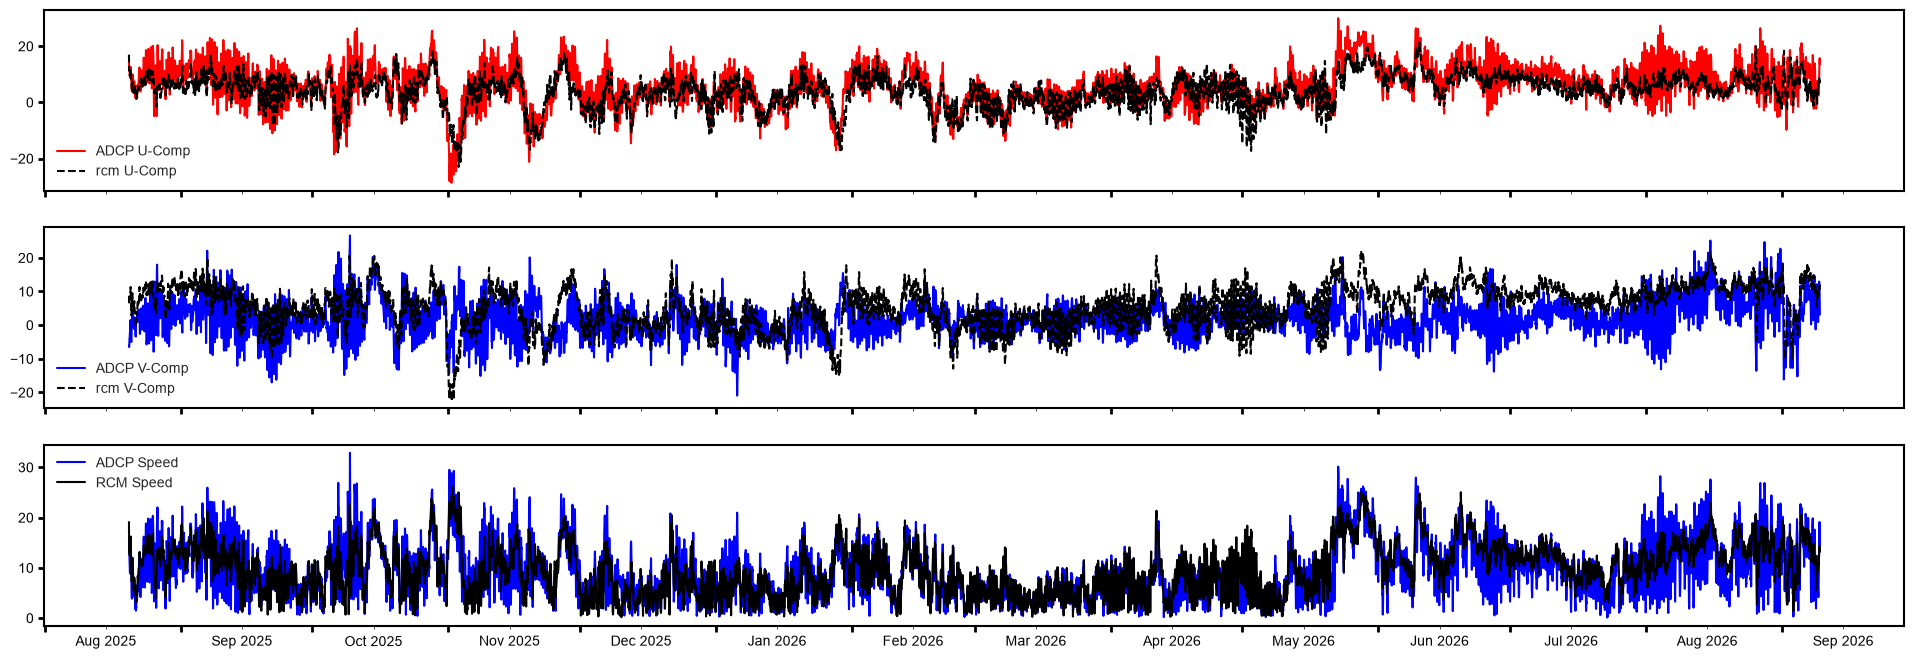

In [9]:
#wrap the plot in image settings for visual appeal
# may be able to make this cleaner or just a preset
# copy is in the notebook examples
%run '../../../settings/mpl_plot_settings.py'

%matplotlib inline
import matplotlib.dates as mdates
from matplotlib.dates import YearLocator, WeekdayLocator, MonthLocator, DayLocator, HourLocator, DateFormatter
import matplotlib.ticker as ticker


fig, ax = plt.subplots(3,figsize=(24, 8),sharex=True)
ax[0].plot(adcp_rcm_depth.index,adcp_rcm_depth.u_curr_comp,color='r',label='ADCP U-Comp')
ax[1].plot(adcp_rcm_depth.index,adcp_rcm_depth.v_curr_comp,color='b',label='ADCP V-Comp')
ax[2].plot(adcp_rcm_depth.index,
           np.sqrt(adcp_rcm_depth.v_curr_comp**2 + adcp_rcm_depth.u_curr_comp**2),
           color='b',label='ADCP Speed')
ax[0].plot(rcm_data.index,rcm_data.u_comp_current,'k--',label='rcm U-Comp')
ax[1].plot(rcm_data.index,rcm_data.v_comp_current,'k--',label='rcm V-Comp')
ax[2].plot(rcm_data.index,
           np.sqrt(rcm_data.v_comp_current**2 + rcm_data.u_comp_current**2),
           color='k',label='RCM Speed')
ax[0].legend()
ax[1].legend()
ax[2].legend()

xfmt = mdates.DateFormatter('%d-%b')
ax[2].xaxis.set_major_locator(DayLocator(bymonthday=1))
ax[2].xaxis.set_minor_locator(DayLocator(bymonthday=15))
ax[2].xaxis.set_minor_formatter(DateFormatter('%b %Y'))
ax[2].xaxis.set_major_formatter(DateFormatter(''))
ax[2].xaxis.set_tick_params(which='major', pad=3)
ax[2].xaxis.set_tick_params(which='minor', pad=5)

fig.savefig(f"images/{mooringid}._ADCPvRCM.png")

In [10]:
from typing import Tuple

def calculate_ts_correlation(
    ts1: pd.Series, 
    ts2: pd.Series, 
    method: str = "pearson"
) -> float:
    """
    Calculates correlation after ensuring time alignment.
    
    Args:
        ts1, ts2: Pandas Series with DatetimeIndex.
        method: Correlation type ('pearson', 'spearman').
    """
    # Alignment: Join on index to ensure we compare the same timestamps
    df = pd.concat([ts1, ts2], axis=1).dropna()
    
    if df.empty:
        raise ValueError("No overlapping time steps found between series.")
        
    return df.corr(method=method).iloc[0, 1]

In [11]:
print(f"U-comp correlation: {calculate_ts_correlation(adcp_rcm_depth.u_curr_comp,rcm_data.u_comp_current,'pearson')}")
print(f"V-comp correlation: {calculate_ts_correlation(adcp_rcm_depth.v_curr_comp,rcm_data.v_comp_current,'pearson')}")
print(f"Speed correlation: {calculate_ts_correlation(np.sqrt(adcp_rcm_depth.v_curr_comp**2 + adcp_rcm_depth.u_curr_comp**2),
                                                      np.sqrt(rcm_data.v_comp_current**2 + rcm_data.u_comp_current**2),'pearson')}")


U-comp correlation: 0.7776883220266759
V-comp correlation: 0.48655949810830385
Speed correlation: 0.7802478867600074
